# 1 · Problem: four fields from real wide-field ODMR


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：odmr_resonance_magnetic_fields

**观测 y：** spectra(1, 2, 2, 300, 480, 51)；frequency_hz(1, 2, 51)；calibration_images(1, 2, 300, 480)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 磁场偶、奇分量和两配置零场分裂四图。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 氮14三Lorentzian共振谱与Zeeman分裂。本地路径为 `solvers.reconstruct→fit(约束LM)`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 8（cell编号按文件内从0计）。章节包括：# 1 · Problem: four fields from real wide-field ODMR；# 2 · Data: full field, independently registered images；# 3 · Physics: splitting, signs and model limits；# 4 · Method: explicit constrained LM, actively rerun；# 5 · Results: four fields, residuals, budgets and fresh robustness；# 6 · Conclusion and interpretation。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 真实磁场GT不可得；1000/10000迭代须区分，配准图不是GT。

<!-- inverse-evidence-audit:20261026:end -->


Two coil configurations and two microwave windows encode projected magnetic splitting and resonance midpoint. We reconstruct the complete 300×480 field, including weak and visibly mismatched spectra.

For configuration $p$, window $r$, frequency $f$ in GHz and three hyperfine components $k$, the conditional model is
$$y_{pr}(f)=1+o_{pr}-\sum_{k=-1}^{1}\frac{C_{prk}w_{pr}^2}{(f-c_{pr}+kA)^2+w_{pr}^2}.$$
Here $c$ is central frequency, $w$ half-width (GHz), $C$ contrast, $o$ offset and $A=0.002158$ GHz. These are measured fluorescence observations, not simulated spectra. No independently measured magnetic truth is available.

The method is a **synchronization-qualified author-method reproduction**: source shared-memory hazards were corrected with barriers and a single writer, without changing the model or LM. Qualified and unchanged original results were actually bitwise identical on this hardware. Neither reference should be called physical truth.

Paper: Volk et al., *QDMlab: A MATLAB toolbox for analyzing quantum diamond microscope (QDM) magnetic field maps*, C&G167105198(2022), DOI10.1016/j.cageo.2022.105198. Selected reference is its author's MIT Python port and MIT Gpufit; the initialization is that port's actual cumulative-sum routine.

In [1]:
from pathlib import Path
import os,sys,time,json,platform,importlib.util
for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS'): os.environ[key]='1'
import numpy as np,matplotlib,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.visualization import sensitivity_experiment,review_figures
print({'kernel':sys.executable,'python':platform.python_version(),'numpy':np.__version__,'matplotlib':matplotlib.__version__})
observations=load_observations(ROOT/'data/raw_data.npz')
print({k:(v.shape,str(v.dtype)) for k,v in observations.items()})


{'kernel': 'D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe', 'python': '3.11.11', 'numpy': '2.4.6', 'matplotlib': '3.11.1'}


{'spectra': ((1, 2, 2, 300, 480, 51), 'float64'), 'frequency_hz': ((1, 2, 51), 'float32'), 'calibration_images': ((1, 2, 300, 480), 'float64')}


# 2 · Data: full field, independently registered images

The two real 1200×1920 camera acquisitions were normalized **per native pixel before** source-supported 4×4 spatial averaging. Every native pixel contributes. The public spectra are already normalized/binned, so they are not normalized a second time. Registered illumination and reflected-light images are acquisition images, not magnetic labels.

Frequency arrays retain source float32 precision. Native headers record 6200 µs exposure and reversed coil settings. Rows increase downward and columns rightward; spatial coordinates are binned pixels because an independent physical pitch is unavailable. Global fluorescence mixing GF is fixed at its source default zero; the resulting fields are conditional apparent fields.

The real raw files were streamed from Harvard Dataverse DOI10.7910/DVN/MPMNZI (CC0), CRC-checked and SHA-256 indexed privately. No target-derived magnetic calibration is supplied.

In [2]:
print('Full input spectra:',observations['spectra'].shape,'curves:',np.prod(observations['spectra'].shape[1:-1]))
print('Frequency windows [GHz]:',observations['frequency_hz'][0][:,[0,-1]]/1e9)
print('Measured intensity range:',observations['spectra'].min(),observations['spectra'].max())


Full input spectra: (1, 2, 2, 300, 480, 51) curves: 576000
Frequency windows [GHz]: [[2.837 2.85 ]
 [2.887 2.9  ]]
Measured intensity range: 0.9828756153185123 0.9999967320772658


# 3 · Physics: splitting, signs and model limits

With source projection signs $s_0=-1,s_1=+1$ and $\gamma=28.024\times10^{-6}$ GHz/µT,
$$b_p=s_p\frac{c_{p1}-c_{p0}}{2\gamma},\quad
B_{\mathrm{even}}=\frac{b_0+b_1}{2},\quad
B_{\mathrm{odd}}=\frac{b_0-b_1}{2},\quad
D_p=\frac{c_{p0}+c_{p1}}{2}.$$
The even field is called remanent; the odd field includes applied bias and bias-dependent sample response. The signs define the dataset projection, not an independently surveyed laboratory axis. $D_p$ is a resonance midpoint, not separately inferred temperature or strain.

Independent analytic Zeeman cases verify both signs. Complex-step differentiation verifies the complete analytic spectral Jacobian. Uncalibrated fluorescence mixing and non-Lorentzian residuals can bias fitted centers: good method parity alone cannot validate the true magnetic field.

# 4 · Method: explicit constrained LM, actively rerun

For all 576000 curves, minimize the unweighted sum of 51 squared residuals. The source's unused configuration string says MLE, but its executed backend call actually defaults to least squares.

With residual $r=d-y$, Jacobian $J$, gradient $g=J^Tr$ and Gauss–Newton matrix $H=J^TJ$, solve
$$(H+\lambda\operatorname{diag}(s))\Delta=g.$$
The scale $s$ retains the maximum past Hessian diagonal. Start $\lambda=0.001$; accept a projected candidate only on strict objective decrease, shrinking damping by 0.1, otherwise increase it by 10. Center/width/contrast bounds and source objective-change stopping are preserved. The primary cap is 10000; the original 1000 default left 94 unfinished curves, all retained below.

The local CPU implementation preserves task-tested float32 reductions and sequential-double Hessian accumulation. Float64 multiply-add followed by float32 conversion approximates contracted arithmetic, with an independently demonstrated double-rounding counterexample; it is not claimed universally exact. Frozen field-error bounds, rather than a universal bit-identity claim, govern reproduction.

The next cell computes both complete reconstructions from observations using only local src. Archived outputs are loaded **after** fresh inversion for labeled comparisons.

In [3]:
started=time.perf_counter()
fresh=reconstruct(observations,max_iterations=10000)
default=reconstruct(observations,max_iterations=1000)
sensitivity=sensitivity_experiment(observations)
print('Primary seconds',fresh['seconds'],'default seconds',default['seconds'],'active total',time.perf_counter()-started)
out=ROOT/'output';out.mkdir(exist_ok=True)
np.savez_compressed(out/'reconstruction.npz',reconstruction=fresh['reconstruction'])
with np.load(ROOT/'notebooks/reference_outputs/upstream_qualified.npz',allow_pickle=False) as z: qualified={k:z[k] for k in z.files}
with np.load(ROOT/'notebooks/reference_outputs/upstream_default_budget.npz',allow_pickle=False) as z: upstream_default={k:z[k] for k in z.files}
spec=importlib.util.spec_from_file_location('independent_review_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(out/'reconstruction.npz')
(out/'judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
assert report['passed'],report
print(json.dumps(report,indent=2))


Primary seconds 114.93307169999753 default seconds 108.89598650000698 active total 224.13851800000702


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "remanent_B_rmse": 5.629461573582625e-06,
    "remanent_B_max_abs": 0.00213623046875,
    "bias_odd_B_rmse": 5.629461573582625e-06,
    "bias_odd_B_max_abs": 0.00213623046875,
    "D_configuration0_rmse": 0.0,
    "D_configuration0_max_abs": 0.0,
    "D_configuration1_rmse": 0.0,
    "D_configuration1_max_abs": 0.0
  },
  "thresholds": {
    "remanent_B_rmse": {
      "comparison": "<=",
      "boundary": 0.02
    },
    "remanent_B_max_abs": {
      "comparison": "<=",
      "boundary": 0.2
    },
    "bias_odd_B_rmse": {
      "comparison": "<=",
      "boundary": 0.02
    },
    "bias_odd_B_max_abs": {
      "comparison": "<=",
      "boundary": 0.2
    },
    "D_configuration0_rmse": {
      "comparison": "<=",
      "boundary": 2e-07
    },
    "D_configuration0_max_abs": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "D_configuration1_rmse": {
      "comparison": "<=",
      "boundary": 2e-07
    },
    "D

# 5 · Results: four fields, residuals, budgets and fresh robustness

The six figure groups preserve complete-field comparisons, original default-budget failures, fresh fits at weak/strong/model-mismatched pixels, every residual and constrained-fit diagnostic, and independent noise perturbations of twelve fixed real pixels. Added noise is review-only; it never replaces the primary real observations.

Field panels use explicit units, common original/fresh ranges and saturation triangles; signed differences use symmetric diverging maps. D panels display MHz relative to 2.87 GHz for readability, while evaluation retains absolute GHz. Histograms and metrics use all fits; the budget quantile panel displays the upper 0.2% tail to reveal sparse changes; the width–residual scatter alone displays every 53rd fit and says so. Original outputs, fresh outputs and noisy controls are separately labeled.

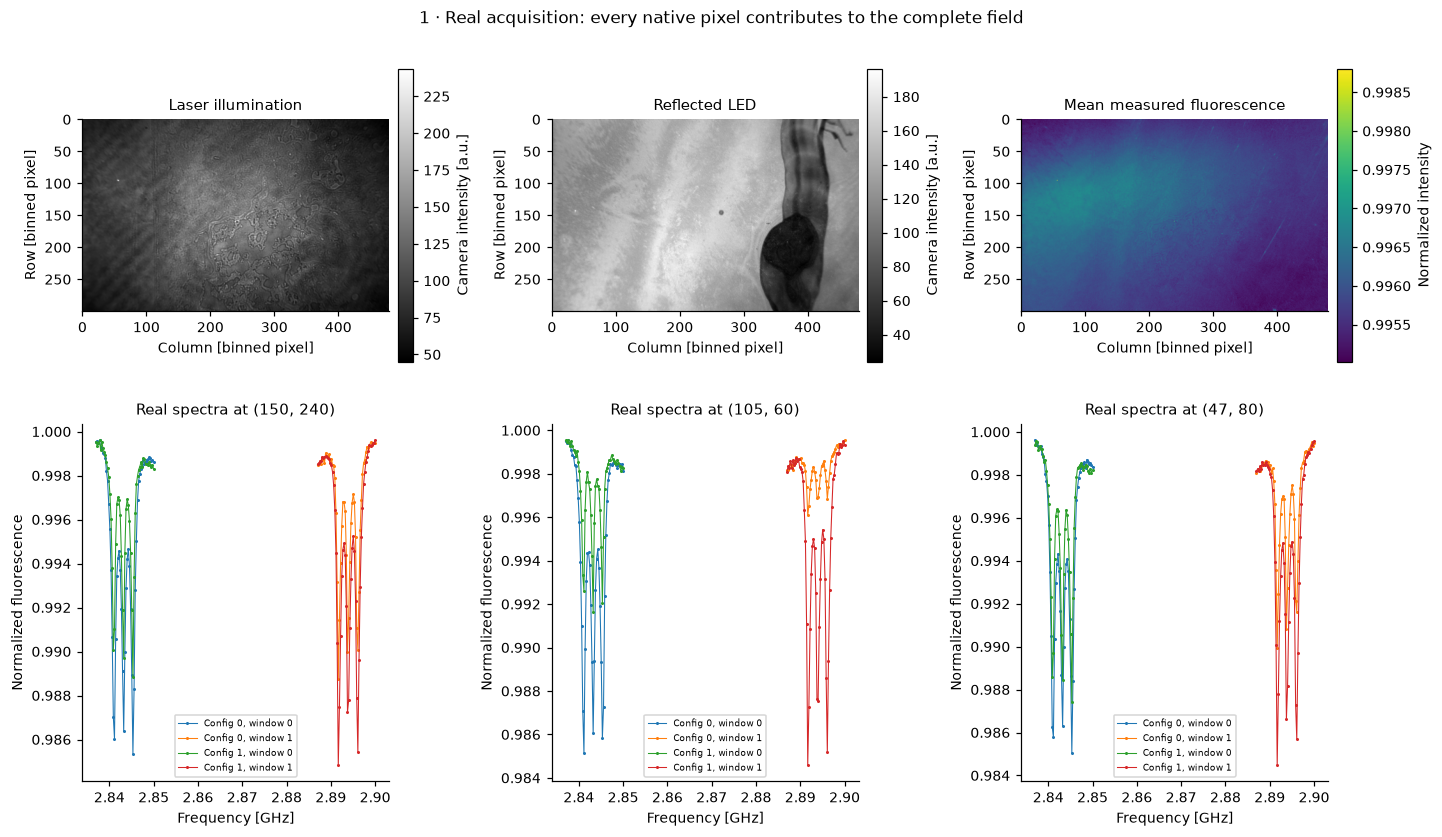

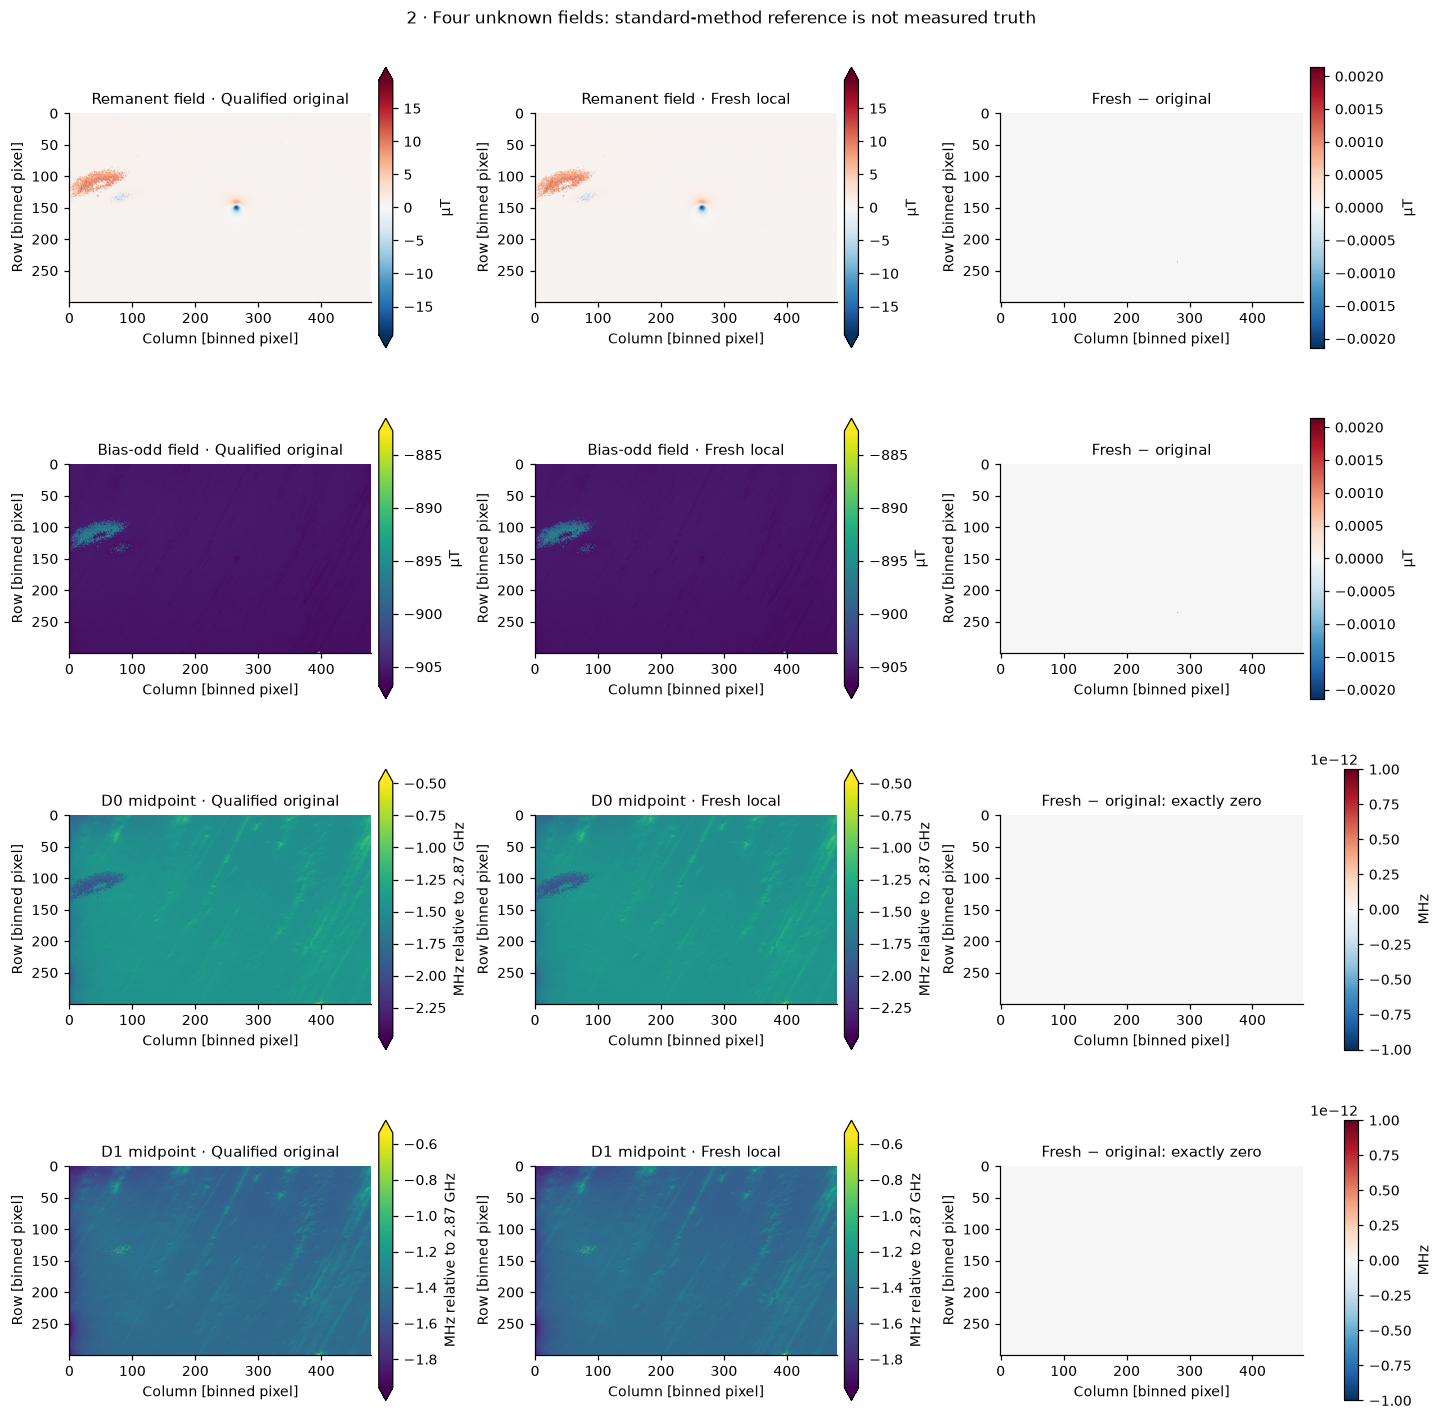

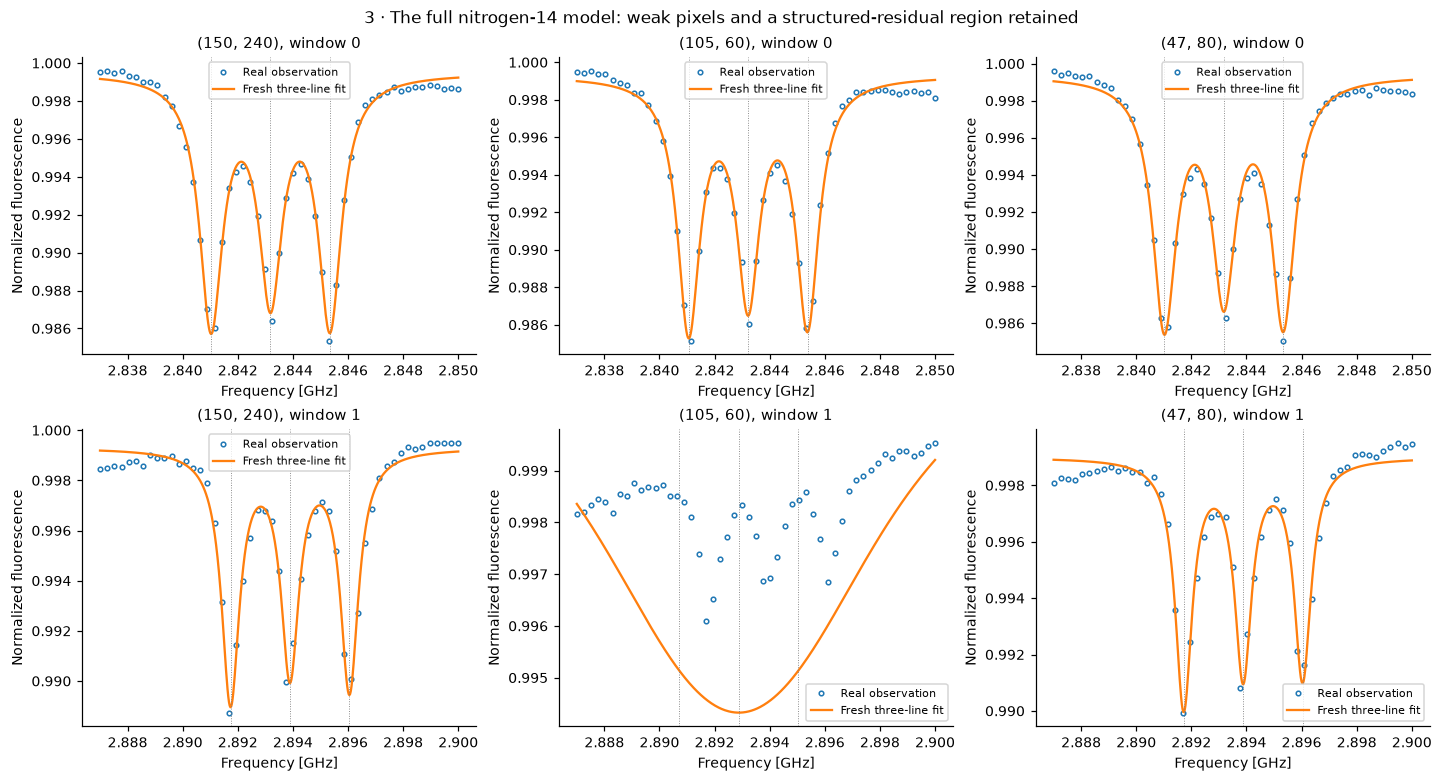

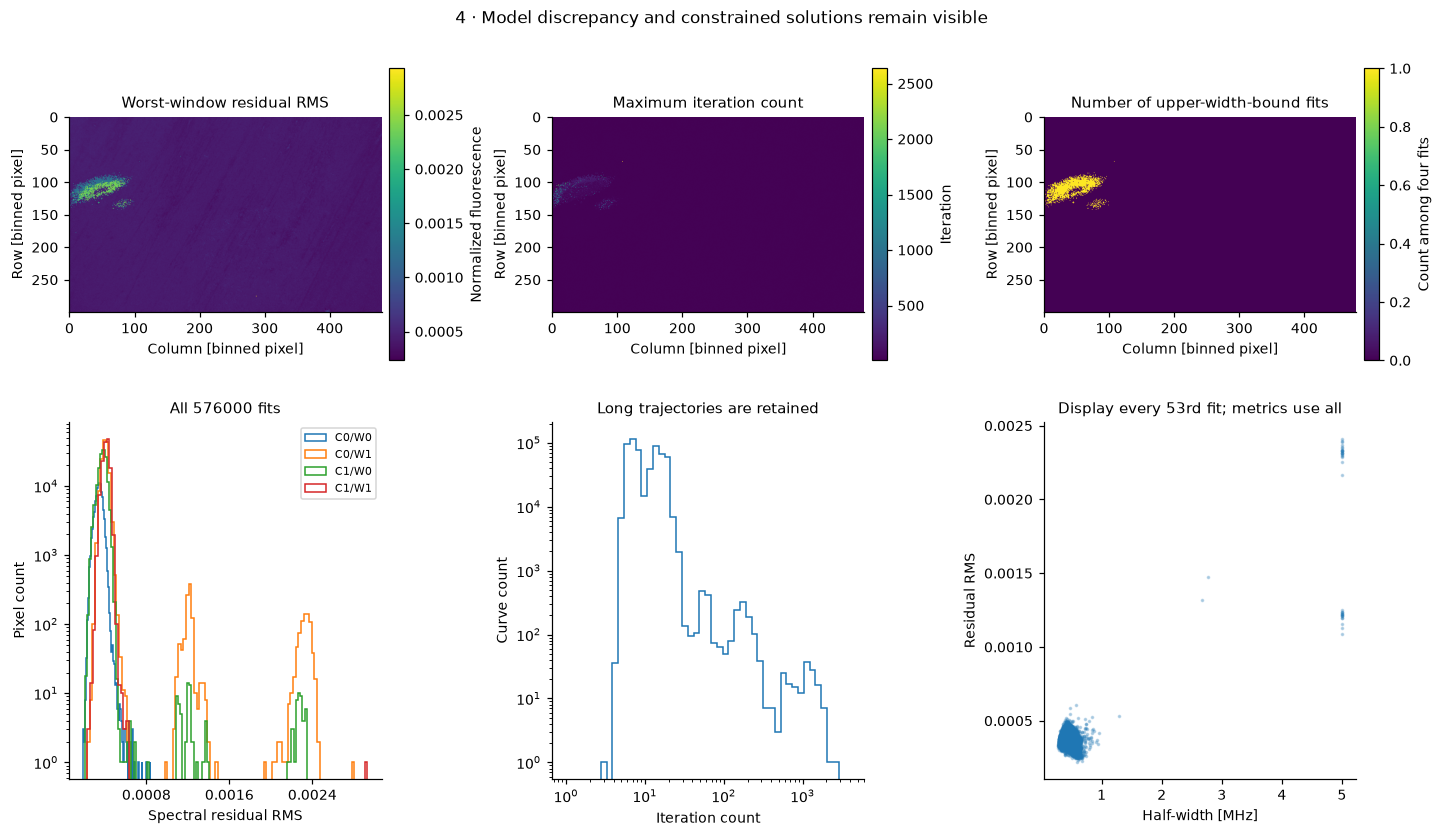

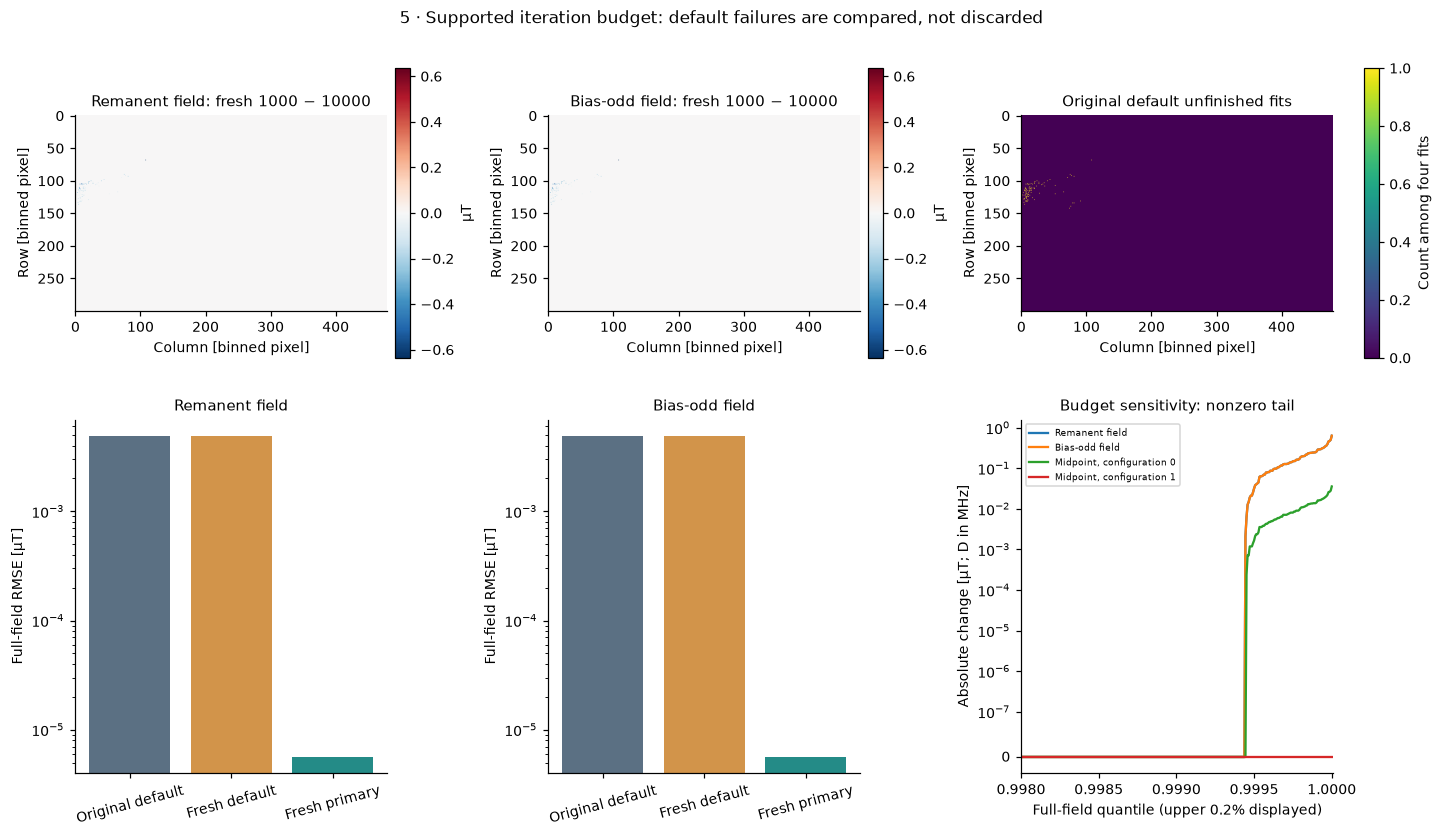

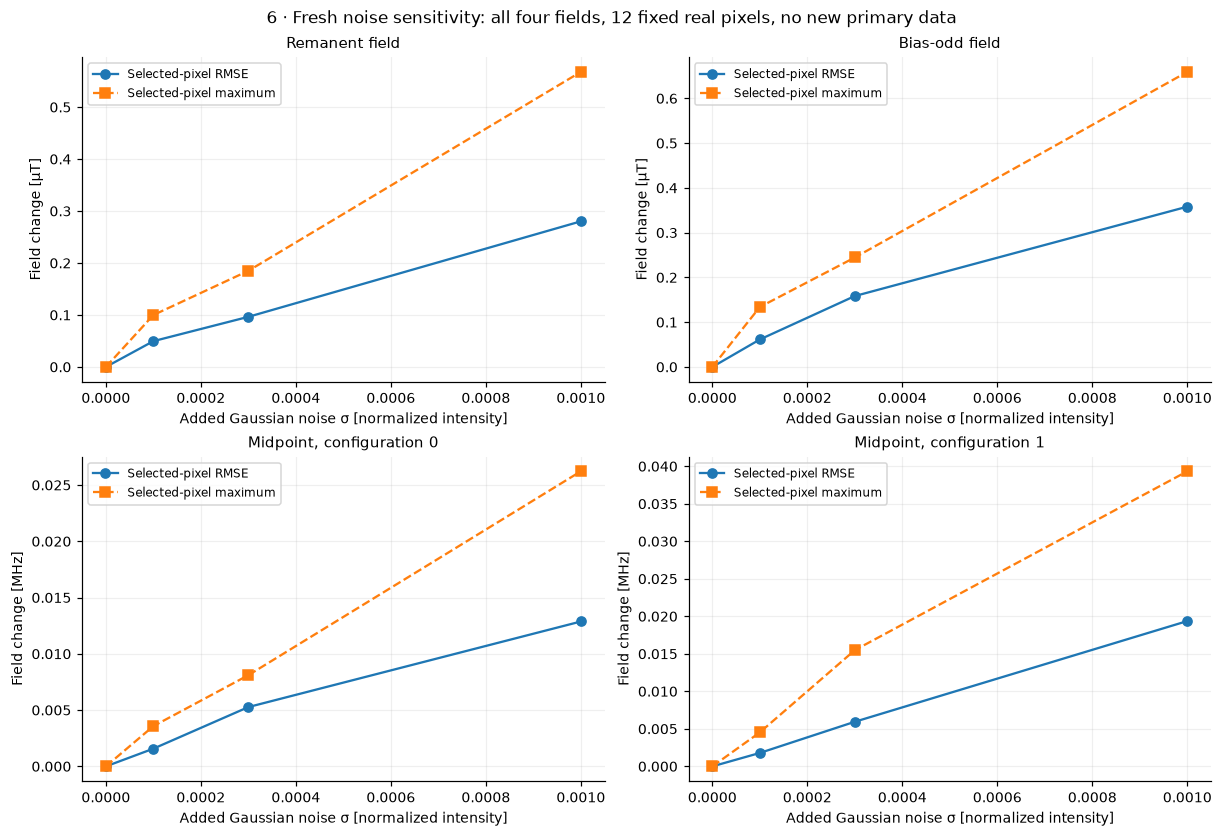

1448

In [4]:
EXPORT=Path('D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research_batch7_20261022\\groups\\physics_materials\\odmr\\figures')
figures=review_figures(observations,fresh,default,qualified,upstream_default,sensitivity,EXPORT)
for fig in figures:
    display(fig)
    plt.close(fig)
(EXPORT/'execution_measurements.json').write_text(json.dumps({'kernel':sys.executable,'numpy':np.__version__,'primary_seconds':fresh['seconds'],'default_seconds':default['seconds'],'judge':report,'full_curves':576000},indent=2),encoding='utf8')

# 6 · Conclusion and interpretation

The complete real acquisition has been freshly inverted and all four required fields evaluated against an independently repeated qualified author-method reference. The full-field comparison retains the large bias offset and never performs hidden registration, rescaling or masking. The default-budget experiment exposes the cost of stopping difficult spectra early; the noise experiment measures sensitivity in all four quantities.

Finite residuals and source-bound fits remain in the results. GF=0, finite frequency sampling, uncertain absolute projection orientation and spectral model discrepancy limit physical interpretation. The inferred remanent/bias-odd projections and resonance midpoints are standard-method results under those assumptions, not independently validated magnetic truth. No strain/temperature separation or pure induced magnetization is claimed.